In [1]:
"""
GOAL: estimate how well and how quickly the CUSUM algorithm converges onto the correct
changepoint time. 

"""

'\nGOAL: estimate how well and how quickly the CUSUM algorithm converges onto the correct\nchangepoint time. \n\n'

In [2]:
import aqua

from aqua.batchAQUA_general import batchAQUA
from aqua.utils import *
from aqua.stimulus import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import convolve, windows
import scipy.stats as stats
from tqdm import tqdm
import pickle
import seaborn as sns
sns.set_theme()

from CPA_with_AQUA import *

In [3]:
#outfile = 'CPA_joblibTest_data.pickle'
tag = 'N100'
outfile = f'CPA_cusum_mean_{tag}_llr_pair.pickle'
SAVE = False

true_cp = 5000

with open(outfile, 'rb') as file:
    data = pickle.load(file)

print(data.head())

print("- - - - - -")
# Need to average the output over trials...


variances = data['variance'].unique()
autapse_f = data['autapse f'].unique()
trial_num = data['N'].unique()

N_neurons = len(autapse_f)
N_noise = len(variances)
N_trials = len(trial_num)

print(f"f: {N_neurons}")
print(f"var: {N_noise}")
print(f"N: {N_trials}")

   N  variance  step_height  autapse f  ISI window     score  change point  \
0  0       0.0            0          0         NaN  0.025578        8835.0   
1  1       0.0            0          0         NaN  0.025578        8835.0   
2  2       0.0            0          0         NaN  0.025578        8835.0   
3  3       0.0            0          0         NaN  0.025578        8835.0   
4  4       0.0            0          0         NaN  0.025578        8835.0   

     method   pre dist  post dist  score per s  divergence  divergence per s  
0  llr_pair  pair_gmm1  pair_gmm1     0.112205    0.009662           0.04238  
1  llr_pair  pair_gmm1  pair_gmm1     0.112205    0.009662           0.04238  
2  llr_pair  pair_gmm1  pair_gmm1     0.112205    0.009662           0.04238  
3  llr_pair  pair_gmm1  pair_gmm1     0.112205    0.009662           0.04238  
4  llr_pair  pair_gmm1  pair_gmm1     0.112205    0.009662           0.04238  
- - - - - -
f: 11
var: 5
N: 100


   autapse f  variance  step_height  weighted |error|  L1 |error|  L2 |error|
0          0       0.0            0            3835.0      3835.0      3835.0
1        100       0.0            0            3936.5      3936.5      3936.5
2        150       0.0            0            2649.1      2649.1      2649.1
3        200       0.0            0             479.2       479.2       479.2
4        220       0.0            0             255.2       255.2       255.2


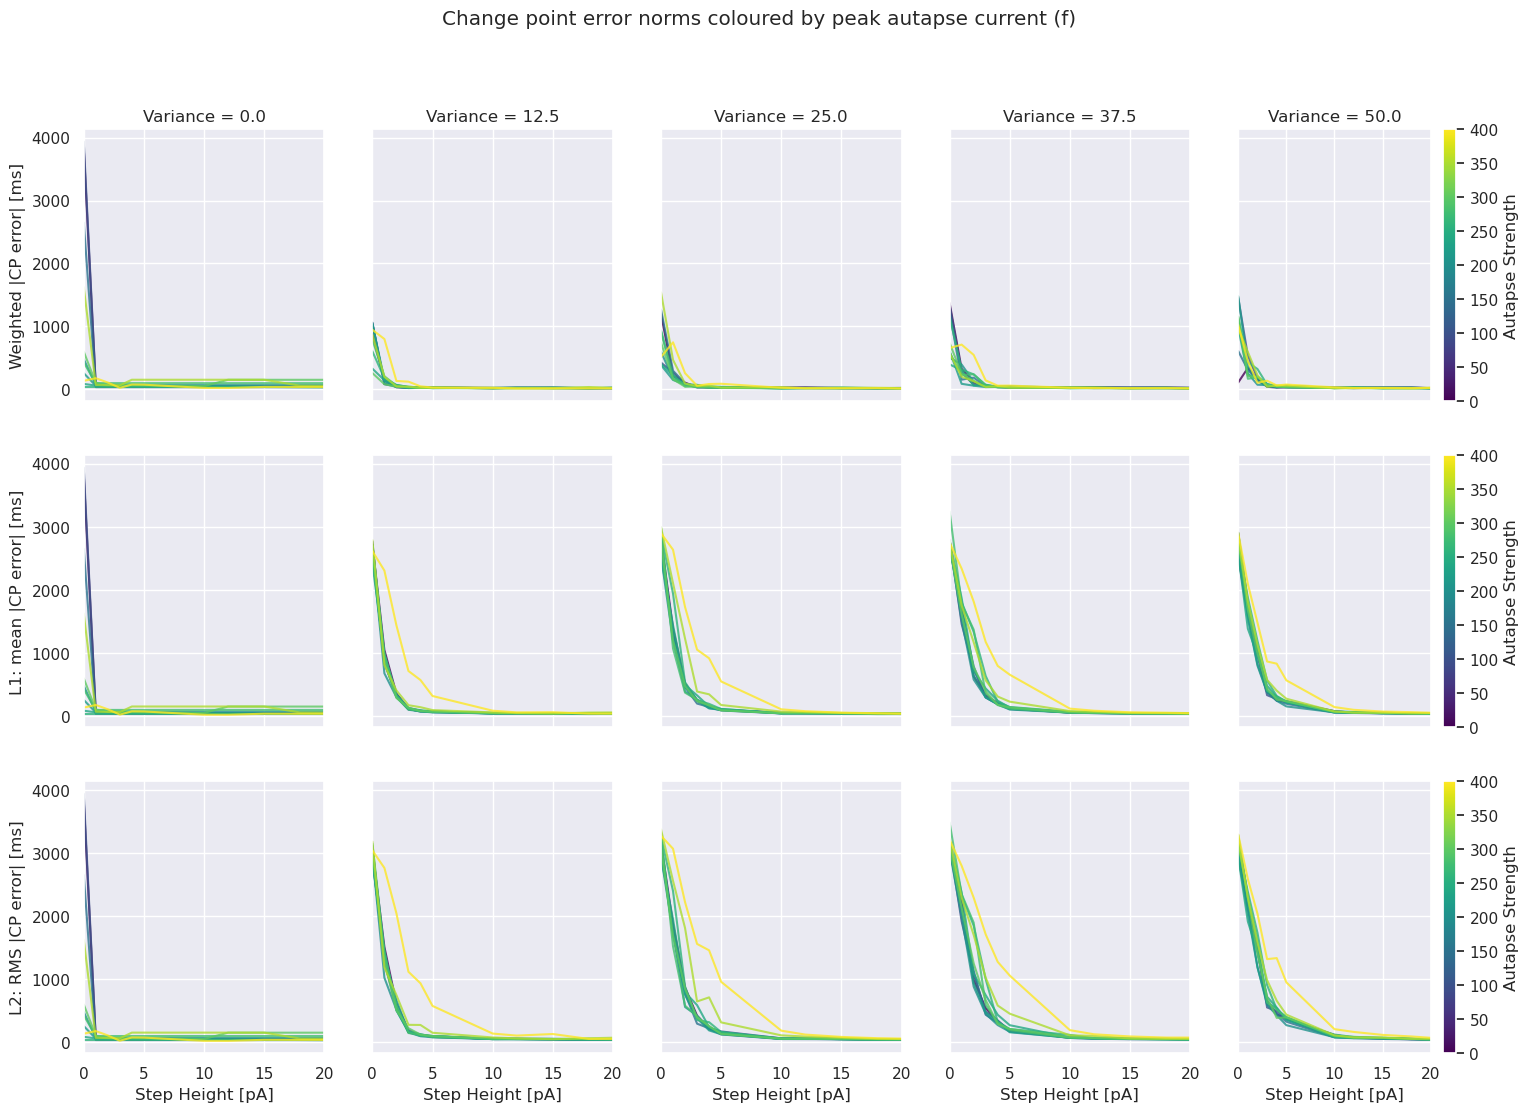

In [4]:
''' WEIGHTED / L1 / L2 NORM CHANGE POINT ERROR '''
# e = |CP - true_cp| per condition (pooled over N); L1 = mean(e), L2 = sqrt(mean(e**2))
# weighted: inverse-distance weights w = 1 / (e + eps), dominated by near-exact hits
group_cols = ['autapse f', 'variance', 'step_height']
acc = weighted_cp_distance(data, true_cp, eps = 1.)
norms = cp_error_norms(data, true_cp)
errs = acc.merge(norms.drop(columns = 'n'), on = group_cols)
print(errs[group_cols + ['weighted |error|', 'L1 |error|', 'L2 |error|']].head())

metrics = {'weighted |error|': 'Weighted |CP error| [ms]',
           'L1 |error|': 'L1: mean |CP error| [ms]',
           'L2 |error|': 'L2: RMS |CP error| [ms]'}

variances = np.sort(errs['variance'].unique())
fig, ax = plt.subplots(len(metrics), len(variances), figsize = (18, 4 * len(metrics)),
                       sharey = 'row', sharex = 'col')

for m, (metric, label) in enumerate(metrics.items()):
    for n, v in enumerate(variances):
        df = errs[errs['variance'] == v]
        fig, ax[m, n] = psychometric_curve(df, x = 'step_height', y = metric, hue = 'autapse f',
                                           fig = fig, ax = ax[m, n], add_colorbar = (n == len(variances) - 1))
        ax[m, n].set_xlim((0, 20))
        ax[m, n].set_ylabel(label if n == 0 else '')
        if m == 0: ax[m, n].set_title(f'Variance = {v}')
        ax[m, n].set_xlabel('Step Height [pA]' if m == len(metrics) - 1 else '')

fig.suptitle('Change point error norms coloured by peak autapse current (f)')

if SAVE: plt.savefig(f'./plots/{tag}_CP_error_norms.png')

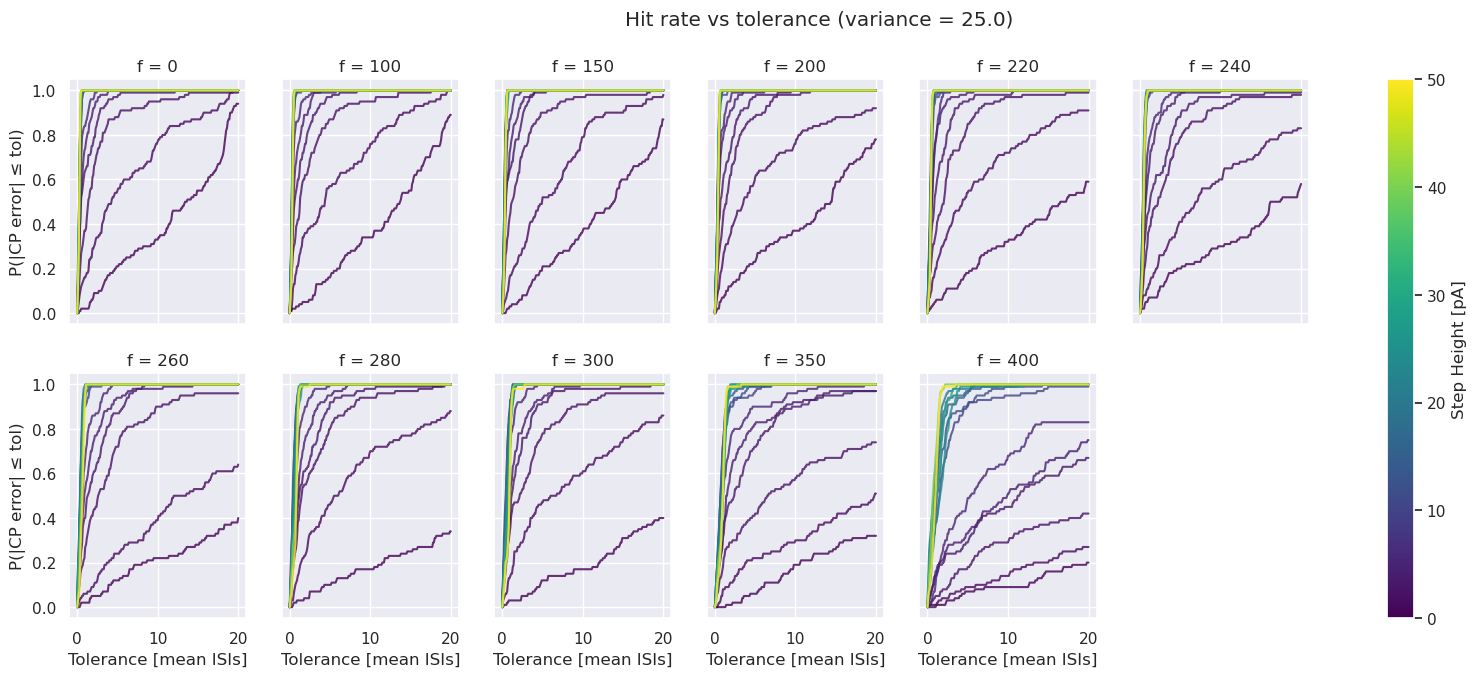

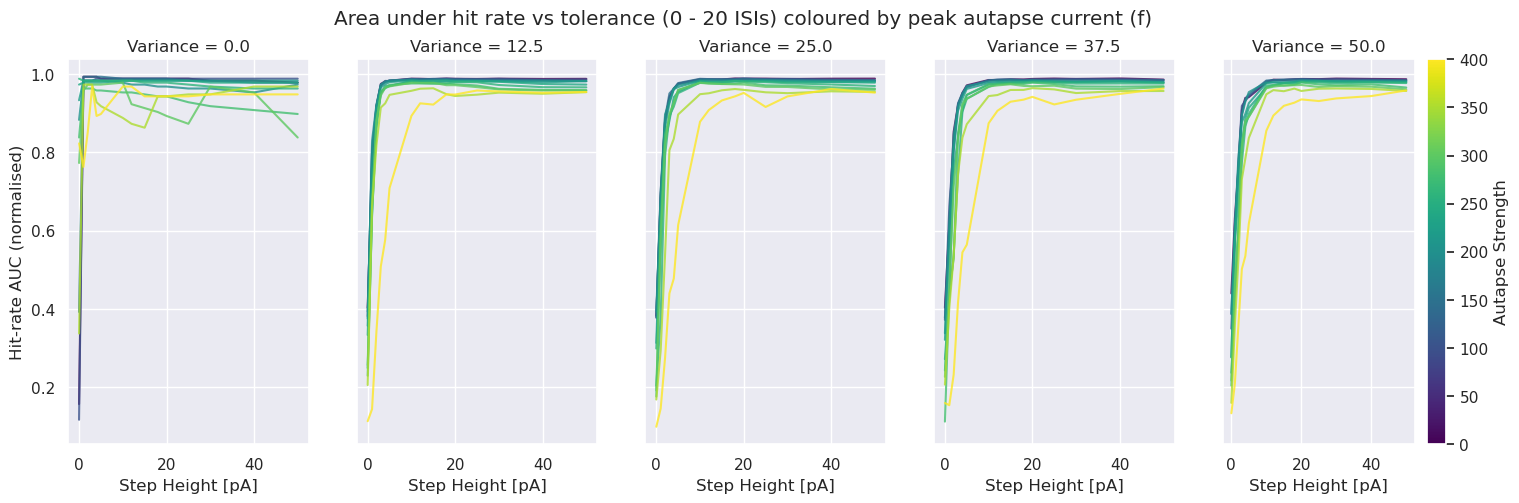

In [5]:
''' HIT RATE vs TOLERANCE: P(|CP - true_cp| <= tol) '''
# tolerance as a constant [ms] or in multiples of each condition's mean ISI (adjusts for firing rate)
TOL_MODE = 'isi'        # 'isi' or 'ms'
tol_max_ms = 1000       # 'ms' mode: tolerances 0 - tol_max_ms
k_max = 20              # 'isi' mode: tolerances 0 - k_max ISIs
v_plot = 25.0           # variance shown in the per-neuron panels (variance 0 is deterministic)

with open(f'CPA_cusum_mean_{tag}_spikes.pickle', 'rb') as file:
    isi_df = mean_isi(pickle.load(file)['spikes'])

if TOL_MODE == 'isi':
    tols, tol_label = np.linspace(0, k_max, 201), 'Tolerance [mean ISIs]'
    hits = hit_rate_curves(data, true_cp, tols, isi_df = isi_df)
else:
    tols, tol_label = np.linspace(0, tol_max_ms, 201), 'Tolerance [ms]'
    hits = hit_rate_curves(data, true_cp, tols)

hit_auc = curve_auc(hits, y = 'hit rate', x = 'tol', group_cols = ('autapse f', 'variance', 'step_height'))

f_vals = np.sort(data['autapse f'].unique())
steps = np.sort(data['step_height'].unique())
step_norm = mcolors.Normalize(vmin = steps.min(), vmax = steps.max())


def per_f_grid(plot_one, title, xlabel, ylabel):
    ''' one panel per autapse f, curves coloured by step height, for variance v_plot '''
    fig, ax = plt.subplots(2, int(np.ceil(len(f_vals) / 2)), figsize = (20, 7), sharex = True, sharey = True)
    for a, f in zip(ax.flat, f_vals):
        plot_one(a, f)
        a.set_title(f'f = {f}')
    for a in ax.flat[len(f_vals):]:
        a.set_visible(False)
    for a in ax[-1]: a.set_xlabel(xlabel)
    for a in ax[:, 0]: a.set_ylabel(ylabel)
    sm = cm.ScalarMappable(cmap = 'viridis', norm = step_norm)
    fig.colorbar(sm, ax = ax, label = 'Step Height [pA]')
    fig.suptitle(f'{title} (variance = {v_plot})')
    return fig, ax


def plot_hits(a, f):
    df = hits[(hits['autapse f'] == f) & (hits['variance'] == v_plot)]
    for h, d_h in df.groupby('step_height'):
        a.plot(d_h['tol'], d_h['hit rate'], color = cm.viridis(step_norm(h)), alpha = 0.8)

fig, ax = per_f_grid(plot_hits, 'Hit rate vs tolerance', tol_label, 'P(|CP error| ≤ tol)')
if SAVE: plt.savefig(f'./plots/{tag}_hit_rate_{TOL_MODE}.png')


variances = np.sort(hit_auc['variance'].unique())
fig, ax = plt.subplots(1, len(variances), figsize = (18, 5), sharey = True)
for n, v in enumerate(variances):
    fig, ax[n] = psychometric_curve(hit_auc[hit_auc['variance'] == v], x = 'step_height', y = 'AUC',
                                    hue = 'autapse f', fig = fig, ax = ax[n],
                                    add_colorbar = (n == len(variances) - 1))
    ax[n].set_title(f'Variance = {v}')
    ax[n].set_xlabel('Step Height [pA]')
ax[0].set_ylabel('Hit-rate AUC (normalised)')
fig.suptitle(f'Area under hit rate vs tolerance (0 - {k_max if TOL_MODE == "isi" else tol_max_ms} '
             f'{"ISIs" if TOL_MODE == "isi" else "ms"}) coloured by peak autapse current (f)')
if SAVE: plt.savefig(f'./plots/{tag}_hit_rate_AUC_{TOL_MODE}.png')

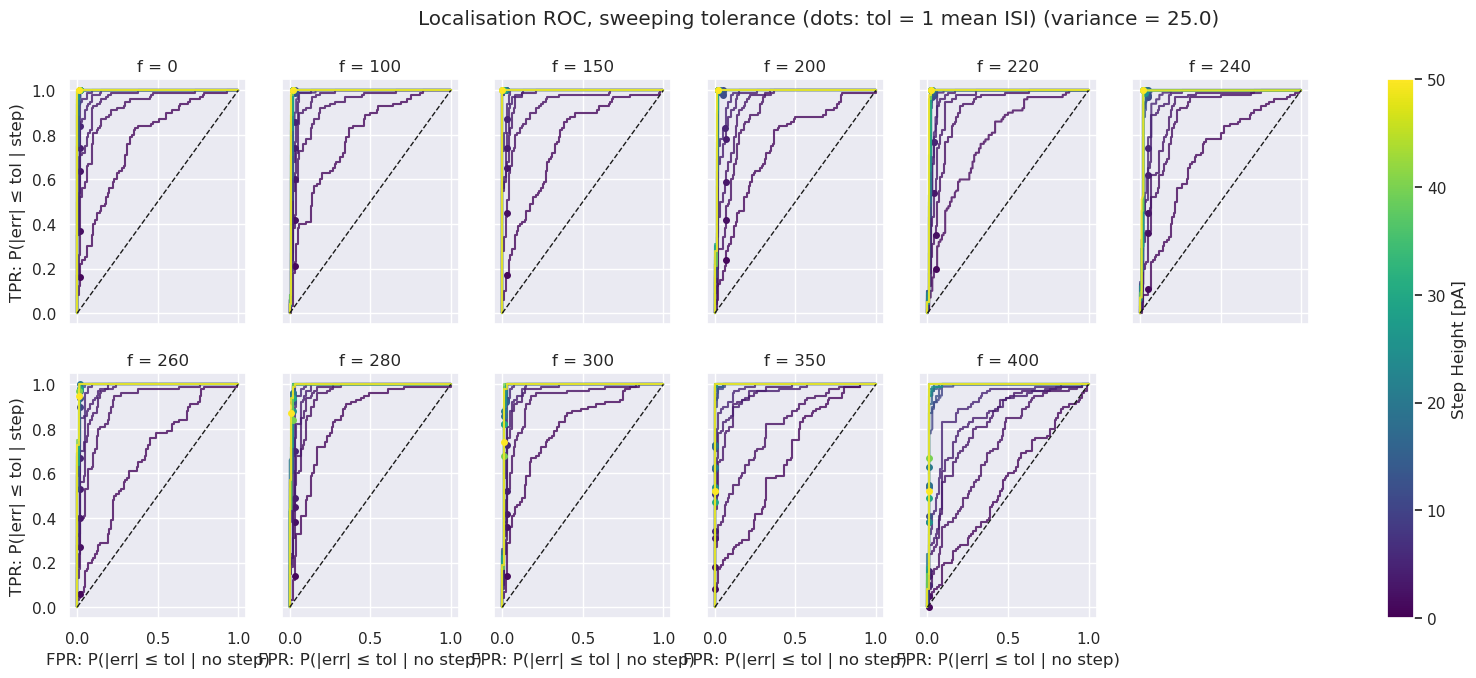

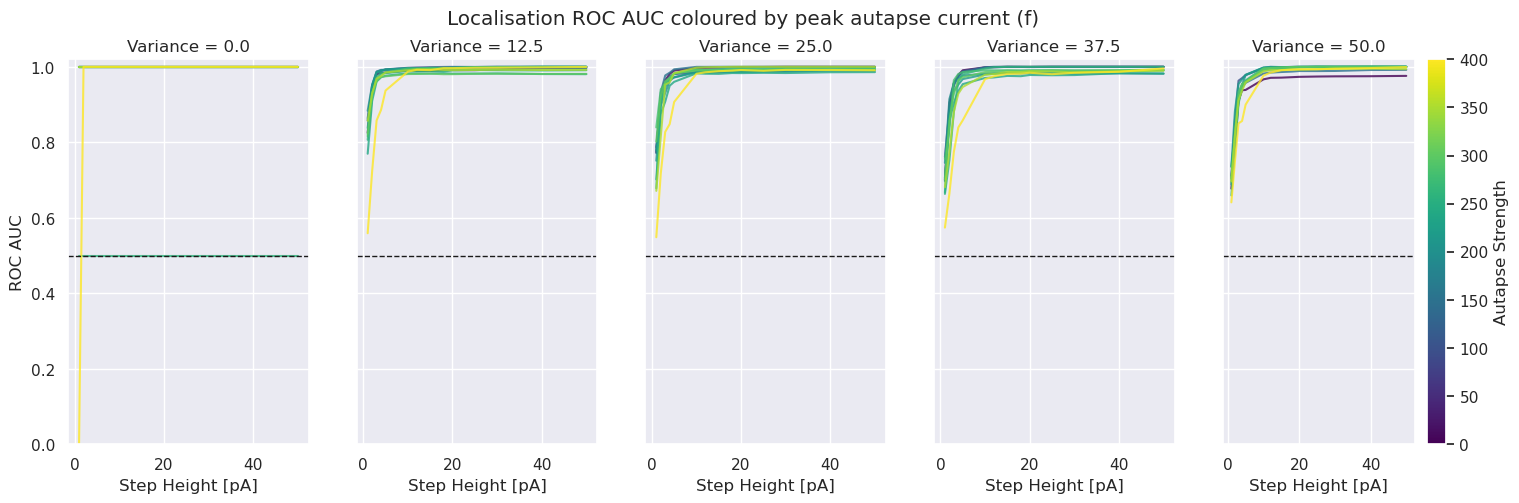

In [6]:
''' NULL-TRIAL ROC: sweep the tolerance '''
# TPR(tol) = P(|err| <= tol | step h),  FPR(tol) = P(|err| <= tol | step 0, same f and variance)
# The ROC / AUC are independent of the tolerance units; TOL_MODE only sets the marked operating point
tol_ref_ms = 100        # 'ms' mode operating point; 'isi' mode marks tol = 1 mean ISI

roc, roc_auc = tolerance_roc(data, true_cp)


def plot_roc(a, f):
    df = roc[(roc['autapse f'] == f) & (roc['variance'] == v_plot)]
    for h, d_h in df.groupby('step_height'):
        c = cm.viridis(step_norm(h))
        a.plot(d_h['FPR'], d_h['TPR'], color = c, alpha = 0.8)
        if TOL_MODE == 'isi':
            sel = (isi_df['variance'] == v_plot) & (isi_df['step_height'] == h) & (isi_df['autapse f'] == f)
            t_ref = isi_df.loc[sel, 'mean ISI'].iloc[0]
        else:
            t_ref = tol_ref_ms
        op = d_h[d_h['tol [ms]'] <= t_ref].iloc[-1]
        a.plot(op['FPR'], op['TPR'], 'o', color = c, markersize = 4)
    a.plot([0, 1], [0, 1], 'k--', lw = 1)

op_label = '1 mean ISI' if TOL_MODE == 'isi' else f'{tol_ref_ms} ms'
fig, ax = per_f_grid(plot_roc, f'Localisation ROC, sweeping tolerance (dots: tol = {op_label})',
                     'FPR: P(|err| ≤ tol | no step)', 'TPR: P(|err| ≤ tol | step)')
if SAVE: plt.savefig(f'./plots/{tag}_tolerance_ROC.png')


variances = np.sort(roc_auc['variance'].unique())
fig, ax = plt.subplots(1, len(variances), figsize = (18, 5), sharey = True)
for n, v in enumerate(variances):
    fig, ax[n] = psychometric_curve(roc_auc[roc_auc['variance'] == v], x = 'step_height', y = 'AUC',
                                    hue = 'autapse f', fig = fig, ax = ax[n],
                                    add_colorbar = (n == len(variances) - 1))
    ax[n].axhline(0.5, color = 'k', ls = '--', lw = 1)
    ax[n].set_ylim((0, 1.02))
    ax[n].set_title(f'Variance = {v}')
    ax[n].set_xlabel('Step Height [pA]')
ax[0].set_ylabel('ROC AUC')
fig.suptitle('Localisation ROC AUC coloured by peak autapse current (f)')
if SAVE: plt.savefig(f'./plots/{tag}_tolerance_ROC_AUC.png')